# Práctica 6 · Mi primer modelo de IA en mi computadora
IN1050 · Herramientas de Procesamiento para IA · Parcial II

En el Parcial I corrieron modelos en Colab, en una computadora de Google. Hoy el modelo corre **en esta computadora**, dentro del entorno virtual `.venv` que crearon con `python -m venv .venv`.

**Antes de correr:** arriba a la derecha, en *Select Kernel*, elijan **Python Environments → .venv**. Después, *Run All*.

In [1]:
# 1. ¿Dónde estoy corriendo? La ruta del intérprete debe terminar en .venv\Scripts\python.exe
import sys, platform
print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
print("Sistema:", platform.system(), platform.release())

Python: 3.13.0
Intérprete: C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\outputs\practica-6\.venv\Scripts\python.exe
Sistema: Windows 11


In [2]:
# 2. Versiones de las bibliotecas (deben coincidir con requirements.txt)
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de las barras de progreso
warnings.filterwarnings("ignore", category=FutureWarning)            # avisos de cambios en versiones futuras
import torch, transformers
from importlib.metadata import version
for paquete in ["torch", "transformers"]:
    print(f"{paquete:14} {version(paquete)}")
print("Hilos de CPU que usa torch:", torch.get_num_threads())

torch          2.15.0
transformers   5.23.0
Hilos de CPU que usa torch: 4


## El modelo
| Dato | Valor |
|---|---|
| Identificador | [google/mobilenet_v2_1.0_224](https://huggingface.co/google/mobilenet_v2_1.0_224) |
| Tarea | `image-classification`: dice qué hay en una foto |
| Parámetros | 3.5 millones (≈ 14 MB): cabe en cualquier computadora |
| Entrenado con | ImageNet: 1,000 categorías, con nombres en inglés |
| Licencia | other (ver la Model Card) |

La primera vez, el modelo se descarga de Hugging Face y se guarda en la caché (`C:\Users\<tú>\.cache\huggingface`). Las siguientes veces se carga de ahí.

In [3]:
# 3. Cargar el modelo (la primera vez lo descarga)
import time
from transformers import pipeline
inicio = time.perf_counter()
clasificador = pipeline("image-classification", model="google/mobilenet_v2_1.0_224")
tiempo_primera_carga = time.perf_counter() - inicio
print(f"Modelo listo en {time.perf_counter() - inicio:.1f} s")

C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\outputs\practica-6\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\work\hf-cache\hub\models--google--mobilenet_v2_1.0_224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warni

C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\outputs\practica-6\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\work\hf-cache\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 6113.61it/s]

Modelo listo en 6.0 s


In [4]:
# Comparación: cargar otra vez, ahora desde la caché local
inicio = time.perf_counter()
clasificador = pipeline("image-classification", model="google/mobilenet_v2_1.0_224", device=-1)
tiempo_segunda_carga = time.perf_counter() - inicio
print(f"Primera carga: {tiempo_primera_carga:.2f} s")
print(f"Segunda carga: {tiempo_segunda_carga:.2f} s")


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 5583.28it/s]

Primera carga: 6.00 s
Segunda carga: 0.33 s


In [5]:
# 4. La función que usa el modelo: recibe la ruta de una imagen y regresa las 3 categorías más probables
def procesar(ruta_imagen):
    inicio = time.perf_counter()
    resultado = clasificador(ruta_imagen, top_k=3)
    segundos = time.perf_counter() - inicio
    return [(r["label"], round(r["score"] * 100, 1)) for r in resultado], segundos

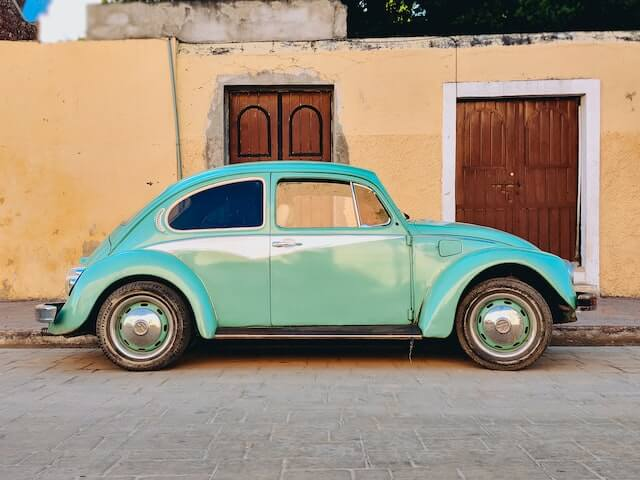

In [6]:
# 5. Una imagen de ejemplo: el modelo también acepta la dirección de una imagen en internet
from pathlib import Path
from IPython.display import Image, display
EJEMPLO = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg"
display(Image(url=EJEMPLO, embed=True, width=320))   # embed: la imagen queda guardada en el cuaderno

In [7]:
# 6. ¿Qué ve el modelo?
categorias, segundos = procesar(EJEMPLO)
for nombre, porcentaje in categorias:
    print(f"{porcentaje:5.1f} %  {nombre}")
print(f"Tiempo: {segundos:.2f} s (incluye bajar la imagen de internet)")

 24.6 %  beach wagon, station wagon, wagon, estate car, beach waggon, station waggon, waggon
 12.5 %  sports car, sport car
 10.0 %  pickup, pickup truck
Tiempo: 0.74 s (incluye bajar la imagen de internet)


## Tu turno
1. Copia una foto tuya (JPG) a esta carpeta, junto a este cuaderno, con el nombre `mi-foto.jpg`.
2. Corre la celda de abajo. Si quieres probar otra, cambia el nombre del archivo.

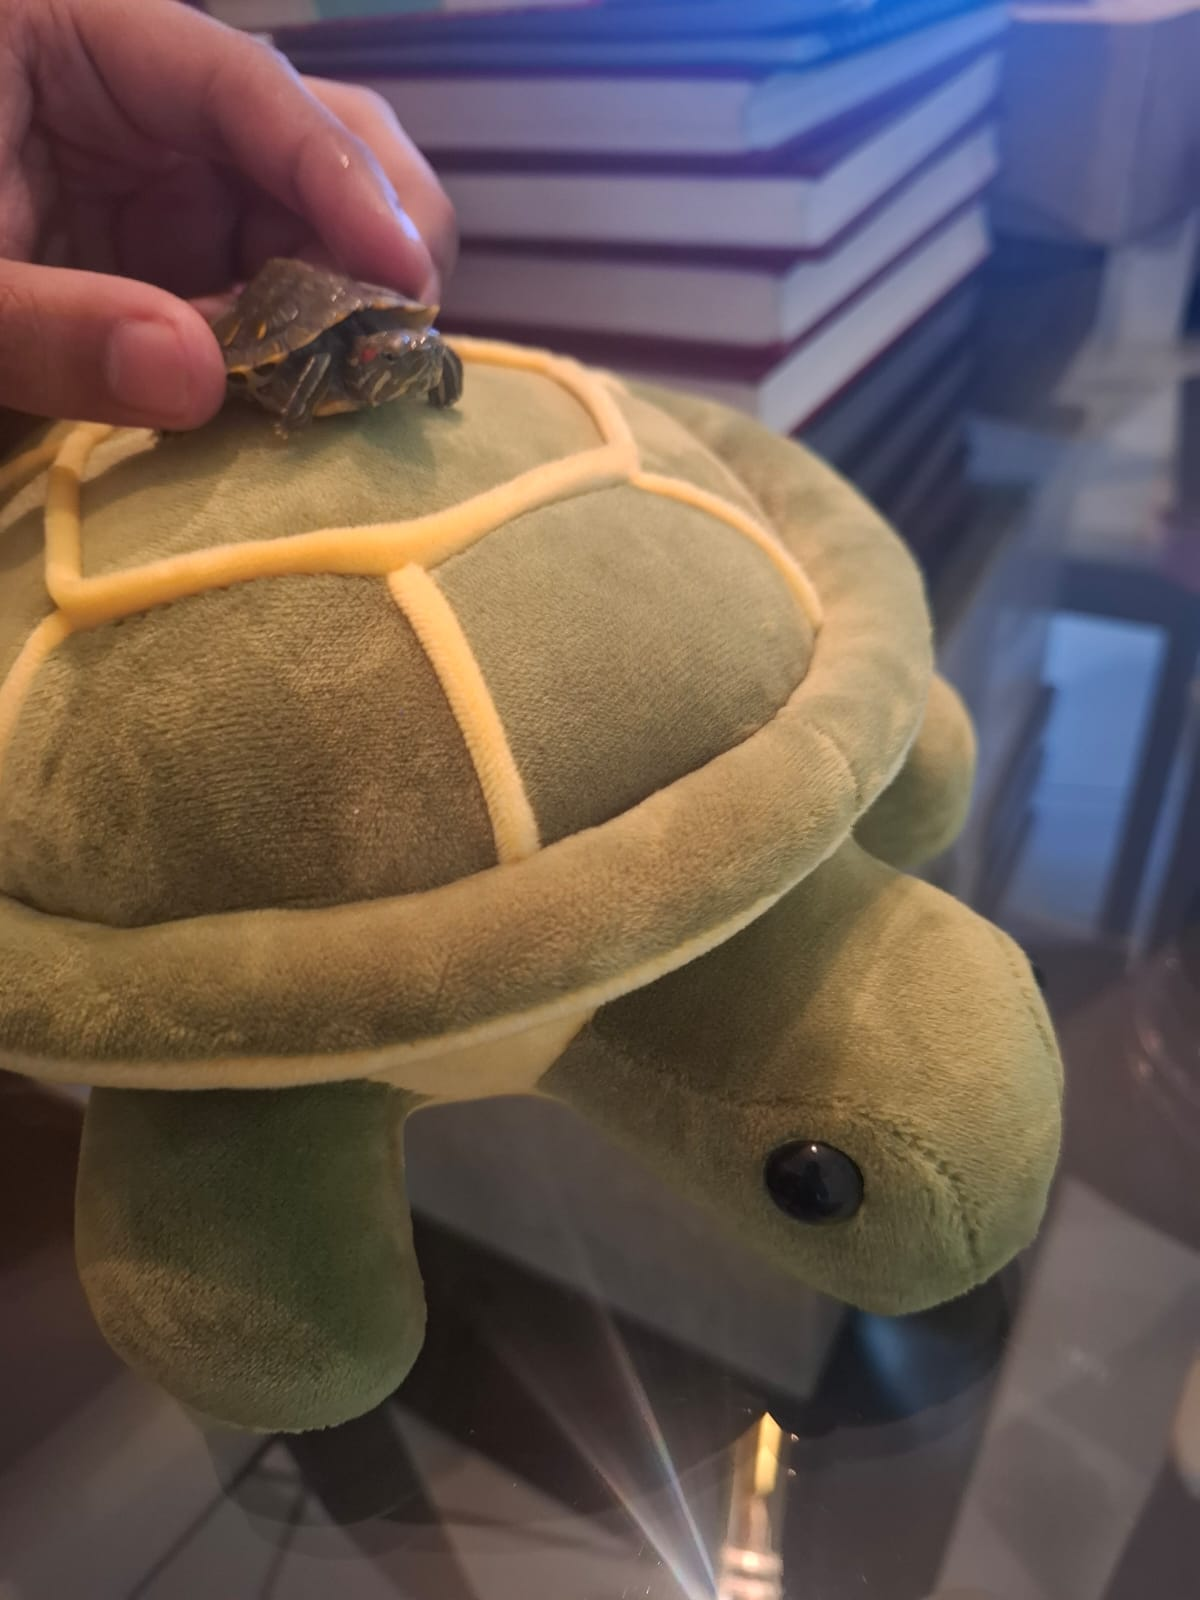

  7.6 %  wooden spoon
  4.9 %  bolete
  2.7 %  artichoke, globe artichoke
Tiempo en CPU: 0.10 s


In [8]:
# 7. Tu foto
mi_foto = Path("mi-foto.jpg")
if mi_foto.exists():
    display(Image(filename=mi_foto, width=320))
    categorias, segundos = procesar(str(mi_foto))
    for nombre, porcentaje in categorias:
        print(f"{porcentaje:5.1f} %  {nombre}")
    print(f"Tiempo en CPU: {segundos:.2f} s")
else:
    print("Todavía no hay mi-foto.jpg en esta carpeta.")

## Preguntas y respuestas

### 1. ¿Qué ruta imprimió la celda 1? ¿Cómo sabes que es el entorno virtual y no el Python de la computadora?

La ruta fue:

`C:\Users\imere\Documents\Codex\2026-11-13\files-mentioned-by-the-user-in1050\outputs\practica-6\.venv\Scripts\python.exe`

Es el entorno virtual porque el ejecutable está dentro de la carpeta `.venv` de este proyecto. La celda muestra Python 3.13.0. `sys.executable` identifica el intérprete que realmente ejecutó el cuaderno; seleccionar ese kernel evita usar las bibliotecas del Python global.

### 2. ¿Cuánto tardó en cargar el modelo la primera vez y cuánto si vuelves a correr la celda 3? ¿Por qué?

En esta ejecución, la primera carga tardó **6.00 segundos** y la segunda **0.33 segundos**. La primera incluyó obtener los archivos del modelo; al cargar de nuevo se reutilizó la caché local y se evitaron descargas repetidas. También pueden influir las cachés del sistema y la inicialización de las bibliotecas. Los tiempos corresponden a esta computadora y esta ejecución, no a los del profesor.

### 3. ¿Acertó con tu foto? ¿Por qué crees que las categorías están en inglés?

**No acertó.** La foto de Grogus muestra una tortuga pequeña sobre un peluche de tortuga. Las tres predicciones fueron:

| Categoría | Puntuación |
|---|---:|
| wooden spoon (cuchara de madera) | 7.6 % |
| bolete (un tipo de hongo) | 4.9 % |
| artichoke, globe artichoke (alcachofa) | 2.7 % |

La inferencia tardó **0.10 segundos**. La tortuga ocupa una parte pequeña de la fotografía, mientras el peluche y el fondo dominan la imagen; esto puede contribuir al error, aunque esta única prueba no demuestra su causa. Una puntuación de 7.6 % es baja y no debe interpretarse como una identificación segura. MobileNetV2 utiliza categorías de ImageNet cuyos nombres están en inglés; no traduce automáticamente sus etiquetas al idioma del usuario.
